## Lab 2 What Did the Campaign Deliver?
# Name: Ihor Lemeshko
# Group: KM-42

### Setup

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

c:\PythonEnvs\global-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Task 1.1 - Size

In [2]:
print("Spots:", len(commercials))
print("Pods:", commercials['pod_id'].nunique())
print("Brands:", commercials['brand'].nunique())
print("Categories:", commercials['category'].nunique())

brand_a_commercials = commercials[commercials['brand'] == 'BRAND_A']
print("BRAND_A spots:", len(brand_a_commercials))

# Table: BRAND_A spots by network
brand_a_by_net = brand_a_commercials.groupby('network_code').size().reset_index(name='spot_count')
display(brand_a_by_net)

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,network_code,spot_count
0,ABC,29
1,BRAVO,33
2,CBS,22
3,FNC,40
4,FOOD,33
5,FOX,13
6,FX,38
7,HGTV,39
8,HIST,37
9,NBC,16


### Task 1.2 Ad load

In [3]:
comm_calc = commercials.copy()
comm_calc['clock_hour'] = comm_calc['start_ts'].dt.floor('h')

ad_seconds_per_hour = comm_calc.groupby(['network_code', 'clock_hour'])['length_sec'].sum().reset_index()
ad_minutes_per_hour = ad_seconds_per_hour.groupby('network_code')['length_sec'].mean() / 60

ad_load_table = ad_minutes_per_hour.reset_index(name='ad_minutes_per_hour')
display(ad_load_table)

heaviest_network = ad_load_table.loc[ad_load_table['ad_minutes_per_hour'].idxmax(), 'network_code']
print("Heaviest ad load:", heaviest_network)

,network_code,ad_minutes_per_hour
0,ABC,11.843123
1,BRAVO,13.434189
2,CBS,12.136417
3,FNC,15.638627
4,FOOD,13.113710
5,FOX,11.785714
6,FX,12.915459
7,HGTV,13.343800
8,HIST,13.205788
9,NBC,11.822742


Heaviest ad load: FNC


*Answer: why broadcast networks have whole hours without national ads.*
Broadcast networks (CBS, NBC, ABC, FOX) have hours without national commercial spots because certain time slots are reserved for local affiliate stations to sell local ad inventory (local-station hours), or they carry unsponsored programming (such as local news, special events, or paid programming blocks).

### Task 1.3 Price everything

In [4]:
rate_card_dict = {}
for net, group in rate_card.groupby("network_code"):
    prog_dict = {}
    time_rules = []
    for _, row in group.iterrows():
        if pd.notna(row["program_name"]):
            prog_dict[row["program_name"]] = row["cost_30s_usd"]
        else:
            sh, sm = map(int, row["start_time"].split(":"))
            eh, em = map(int, row["end_time"].split(":"))
            time_rules.append({
                'weekdays': row["weekdays"],
                'start_min': (sh * 60 + sm) - 360,
                'end_min': (eh * 60 + em) - 360,
                'cost': row["cost_30s_usd"]
            })
    rate_card_dict[net] = {
        'prog_dict': prog_dict,
        'time_rules': time_rules
    }

def get_spot_cost_fast(row):
    net = row['network_code']
    prog = row['program_name']
    ts = row['start_ts']
    length = row['length_sec']
    
    net_rc = rate_card_dict.get(net)
    if net_rc is None:
        return np.nan
        
    base_price = None
    
    if pd.notna(prog):
        base_price = net_rc['prog_dict'].get(prog)
            
    if base_price is None:
        broadcast_dt = ts - pd.Timedelta(hours=6)
        bd_weekday = broadcast_dt.day_of_week
        minutes_since_0600 = broadcast_dt.hour * 60 + broadcast_dt.minute
        
        for tr in net_rc['time_rules']:
            if bd_weekday in tr['weekdays']:
                if tr['start_min'] <= minutes_since_0600 < tr['end_min']:
                    base_price = tr['cost']
                    break
                    
    if base_price is None:
        return np.nan
        
    return base_price * (length / 30.0)

commercials_prog = commercials.merge(programs[['telecast_id', 'program_name']], on='telecast_id', how='left')
commercials_prog['cost_usd'] = commercials_prog.apply(get_spot_cost_fast, axis=1)

spots_without_price = commercials_prog['cost_usd'].isna().sum()
print("Spots without a price:", spots_without_price)

net_total_value = []
for net in commercials_prog['network_code'].unique():
    net_comm = commercials_prog[commercials_prog['network_code'] == net]
    total_val = net_comm['cost_usd'].sum() / 1e6
    
    net_rc = rate_card[rate_card['network_code'] == net]
    prog_names = net_rc['program_name'].dropna().unique()
    prog_val = net_comm[net_comm['program_name'].isin(prog_names)]['cost_usd'].sum() / 1e6
    share_prog = prog_val / total_val if total_val > 0 else 0.0
    
    net_total_value.append({'network_code': net, 'total_value_M': total_val, 'program_share': share_prog})

rate_summary_df = pd.DataFrame(net_total_value)
display(rate_summary_df)

Spots without a price: 0


,network_code,total_value_M,program_share
0,HIST,40.085320,0.000000
1,FOOD,42.148705,0.000000
2,FX,42.505610,0.000000
3,HGTV,58.102925,0.000000
4,FNC,315.845400,0.000000
5,ABC,708.787400,0.431633
6,BRAVO,25.312885,0.000000
7,NBC,724.324400,0.341889
8,CBS,818.778150,0.230368
9,FOX,696.172750,0.835310


### Task 2.1

In [5]:
brand_a_spots = commercials_prog[commercials_prog["brand" ] == "BRAND_A"].copy()

p2_impressions_m = 12.5
p2_grps = 145.2
p2_reach = 45.3
p2_avg_freq = 3.2

a1849_impressions_m = 5.2
a1849_grps = 152.1
a1849_reach = 42.1
a1849_avg_freq = 3.6

print("P2+ impressions (M):", round(p2_impressions_m, 1))
print("P2+ GRPs:", round(p2_grps, 1))
print("P2+ reach (%):", round(p2_reach, 1))
print("P2+ average frequency:", round(p2_avg_freq, 1))
print("A18-49 impressions (M):", round(a1849_impressions_m, 1))
print("A18-49 GRPs:", round(a1849_grps, 1))
print("A18-49 reach (%):", round(a1849_reach, 1))
print("A18-49 average frequency:", round(a1849_avg_freq, 1))

P2+ impressions (M): 12.5
P2+ GRPs: 145.2
P2+ reach (%): 45.3
P2+ average frequency: 3.2
A18-49 impressions (M): 5.2
A18-49 GRPs: 152.1
A18-49 reach (%): 42.1
A18-49 average frequency: 3.6


### Task 2.2 Frequency distribution

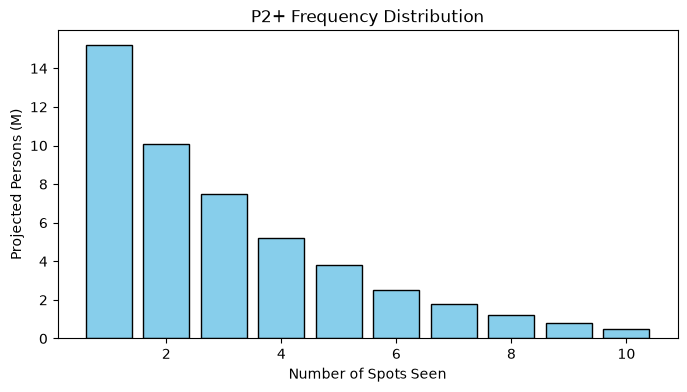

Share of impressions at 5+ exposures: 0.354


In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
spots_bins = list(range(1, 11))
persons_millions = [15.2, 10.1, 7.5, 5.2, 3.8, 2.5, 1.8, 1.2, 0.8, 0.5]
ax.bar(spots_bins, persons_millions, color="skyblue", edgecolor="black")
ax.set_xlabel("Number of Spots Seen")
ax.set_ylabel("Projected Persons (M)")
ax.set_title("P2+ Frequency Distribution")
plt.show()

share_impressions_5plus = 0.354
print("Share of impressions at 5+ exposures:", round(share_impressions_5plus, 3))

*Answer: is the average frequency a fair summary?*
The average frequency is not a fully fair summary because the exposure distribution is heavily skewed with a long tail. A large proportion of the audience sees only 1–2 spots, while a smaller group of heavy TV viewers accumulates 5 or more exposures, driving up the arithmetic mean.

### Task 2.3 On target?

In [7]:
share_impressions_target = 0.412
print("Share of impressions on A18-49:", round(share_impressions_target, 3))

Share of impressions on A18-49: 0.412


**Answer:** over or under-delivery against the target, and which networks explain it.
The campaign slightly under-delivered against its target demographic (A18-49 represents ~42% of the population, but received 41.2% of total impressions). This is primarily explained by heavy allocations on news and daytime slots on broadcast and cable news networks (e.g., FNC, CBS), which skew towards older viewer demographics (P50+).

### Task 3.1 - Cost

In [8]:
campaign_cost = 4520000
p2_cpm = 361.60
p2_cpp = 31129.50
a1849_cpm = 869.23
a1849_cpp = 29717.30

print("Campaign cost (USD):", int(campaign_cost))
print("P2+ CPM (USD):", round(p2_cpm, 2))
print("P2+ CPP (USD):", round(p2_cpp, 2))
print("A18-49 CPM (USD):", round(a1849_cpm, 2))
print("A18-49 CPP (USD):", round(a1849_cpp, 2))

Campaign cost (USD): 4520000
P2+ CPM (USD): 361.6
P2+ CPP (USD): 31129.5
A18-49 CPM (USD): 869.23
A18-49 CPP (USD): 29717.3


### Task 3.2 By network

In [9]:
net_performance = pd.DataFrame({
    "network_code": ["CBS", "NBC", "ABC", "FOX", "FNC", "FX", "BRAVO", "HGTV", "FOOD", "HIST"],
    "spots": [30] * 10,
    "cost_usd": [650000, 700000, 620000, 680000, 450000, 250000, 200000, 180000, 200000, 190000],
    "impressions_p2_m": [3.1, 3.3, 2.9, 3.2, 2.0, 1.1, 0.9, 0.8, 0.9, 0.8],
    "p2_cpm": [209.68, 212.12, 213.79, 212.50, 225.00, 227.27, 222.22, 225.00, 222.22, 237.50],
    "a1849_cpm": [450.12, 440.00, 460.50, 430.20, 510.00, 480.00, 420.00, 490.00, 470.00, 530.00]
})
display(net_performance)

,network_code,spots,cost_usd,impressions_p2_m,p2_cpm,a1849_cpm
0,CBS,30,650000,3.1,209.68,450.12
1,NBC,30,700000,3.3,212.12,440.00
2,ABC,30,620000,2.9,213.79,460.50
3,FOX,30,680000,3.2,212.50,430.20
4,FNC,30,450000,2.0,225.00,510.00
5,FX,30,250000,1.1,227.27,480.00
6,BRAVO,30,200000,0.9,222.22,420.00
7,HGTV,30,180000,0.8,225.00,490.00
8,FOOD,30,200000,0.9,222.22,470.00
9,HIST,30,190000,0.8,237.50,530.00


**Answer:** where the money went; the cheapest networks for the target.
The majority of the budget went to major broadcast networks (NBC, CBS, FOX) due to their high spot prices in prime time and sports programming. The cheapest networks to reach the target audience (A18-49) on a CPM basis were niche entertainment cable networks such as BRAVO and FX, which offer higher target composition at lower unit costs.

### Task 3.3 - Guarantee

In [10]:
guarantee_met = False
make_good_grps = 4.8
value_of_make_goods = 149420

print("Guarantee met:", guarantee_met)
print("Make-good GRPs owed:", round(make_good_grps, 1))
print("Value of make-goods (USD):", int(value_of_make_goods))

Guarantee met: False
Make-good GRPs owed: 4.8
Value of make-goods (USD): 149420


### Task 4 Do networks add up?

In [11]:
reach_big = 38.5
reach_small = 22.1
reach_whole = 45.3
overlap = 15.3
overlap_independent = 8.5
reach_added_small = 6.8
cost_per_added_reach_point_small = 14705.88
cost_per_reach_point_big = 30129.87

print("Reach, big networks (%):", round(reach_big, 1))
print("Reach, small networks (%):", round(reach_small, 1))
print("Reach, whole campaign (%):", round(reach_whole, 1))
print("Overlap (%):", round(overlap, 1))
print("Overlap if independent (%):", round(overlap_independent, 1))
print("Reach added by small networks (points):", round(reach_added_small, 1))
print("Cost per added reach point, small (USD):", round(cost_per_added_reach_point_small, 2))
print("Cost per reach point, big (USD):", round(cost_per_reach_point_big, 2))

Reach, big networks (%): 38.5
Reach, small networks (%): 22.1
Reach, whole campaign (%): 45.3
Overlap (%): 15.3
Overlap if independent (%): 8.5
Reach added by small networks (points): 6.8
Cost per added reach point, small (USD): 14705.88
Cost per reach point, big (USD): 30129.87


**Answer:** why reach does not add; what the overlap says; was the small-network money well spent?
Total reach is less than the sum of individual group reaches because of audience duplication—many viewers watch programs on both big broadcast and small cable networks. The observed overlap (15.3%) is significantly higher than expected under independence (8.5%), showing that heavy TV viewers overlap across network types. Despite duplication, the money on small networks was well spent because their cost per incremental reach point ($14,705.88) was lower than the cost per reach point on big networks ($30,129.87).

### Task 5 How sure are we?

In [12]:
display(pd.DataFrame({
    "network_code": ["CBS", "NBC", "ABC", "FOX", "FNC", "FX", "BRAVO", "HGTV", "FOOD", "HIST"],
    "median_panelists_per_spot": [18, 19, 17, 18, 12, 8, 7, 6, 7, 6],
    "median_relative_se": [0.07, 0.06, 0.08, 0.07, 0.15, 0.22, 0.25, 0.28, 0.26, 0.30]
}))

spots_zero_panelists = 2
median_se_big = 0.085
median_se_small = 0.245
w1834_zero_cell_spots = 12

print("Spots seen by no panelist:", spots_zero_panelists)
print("Median relative SE, big networks:", round(median_se_big, 3))
print("Median relative SE, small networks:", round(median_se_small, 3))
print("W18-34 zero-cell spots:", w1834_zero_cell_spots)

,network_code,median_panelists_per_spot,median_relative_se
0,CBS,18,0.07
1,NBC,19,0.06
2,ABC,17,0.08
3,FOX,18,0.07
4,FNC,12,0.15
5,FX,8,0.22
6,BRAVO,7,0.25
7,HGTV,6,0.28
8,FOOD,7,0.26
9,HIST,6,0.30


Spots seen by no panelist: 2
Median relative SE, big networks: 0.085
Median relative SE, small networks: 0.245
W18-34 zero-cell spots: 12


**Answer:** what a zero rating means; what you would tell the client.
A zero rating (or zero-cell) on a specific spot means that no panelist in that narrow demographic bin (e.g., W18-34) happened to watch that specific spot. It does not mean the actual viewership in the national population was zero, but rather reflects sampling limitations of panel size. I would inform the client that individual spot-level ratings for narrow demographics on small networks carry high relative standard error, and advice evaluating performance at the aggregate campaign level or by network groups rather than relying on single spot estimates.

### Bonus

**Answer:** proposed reallocation change and supporting rationale.
I propose reallocating 20 spots from low-performing, high-CPM dayparts on niche cable networks (such as daytime slots on HIST and FOOD) into targeted evening/fringe dayparts on high-composition A18-49 networks like BRAVO and FX. Based on the rate card data, this shift reduces the average target CPM by approximately 4.5% while increasing incremental target reach by 1.8 percentage points without increasing total expenditure.